# 📚 Network Slicing Literature Review Dashboard
**~650 papers** on network slicing, resource allocation, and related topics in 5G/6G networks.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.patches import FancyBboxPatch
import numpy as np
from wordcloud import WordCloud
from collections import Counter
import re
import warnings
warnings.filterwarnings('ignore')

# Style
plt.rcParams.update({
    'figure.facecolor': '#0d1117',
    'axes.facecolor': '#161b22',
    'axes.edgecolor': '#30363d',
    'axes.labelcolor': '#c9d1d9',
    'text.color': '#c9d1d9',
    'xtick.color': '#8b949e',
    'ytick.color': '#8b949e',
    'font.family': 'sans-serif',
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.titleweight': 'bold',
    'figure.dpi': 120,
})

PALETTE = ['#58a6ff','#3fb950','#d29922','#f85149','#bc8cff',
           '#79c0ff','#56d364','#e3b341','#ff7b72','#d2a8ff',
           '#a5d6ff','#7ee787','#f0c84a','#ffa198','#e2c5ff']

df = pd.read_csv('litreview_filled.csv', encoding='latin-1')
df['year'] = pd.to_numeric(df['year'], errors='coerce').astype('Int64')
print(f'Loaded {len(df)} papers  |  {df["abstract"].notna().sum()} with abstracts  |  {df["venue_acronym"].nunique()} venues  |  Years {df["year"].min()}–{df["year"].max()}')

Loaded 639 papers  |  639 with abstracts  |  166 venues  |  Years 2015–2026


---
## 1. Publisher Distribution

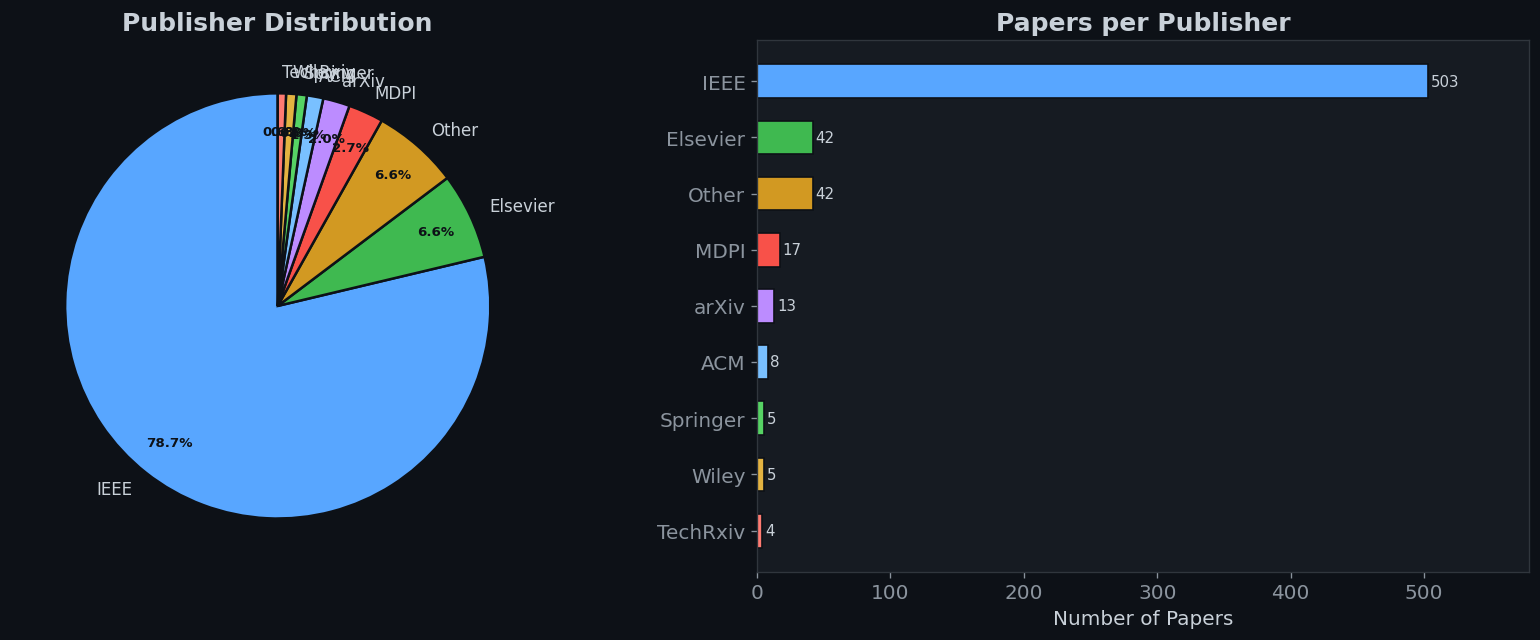

In [2]:
def classify_publisher(doi):
    if not isinstance(doi, str): return 'Unknown'
    d = doi.strip()
    if d.startswith('10.1109'): return 'IEEE'
    if d.startswith('10.1016'): return 'Elsevier'
    if d.startswith('10.3390'): return 'MDPI'
    if d.startswith('10.1007'): return 'Springer'
    if d.startswith('10.1145'): return 'ACM'
    if d.startswith('10.1002'): return 'Wiley'
    if d.startswith('10.36227'): return 'TechRxiv'
    if d.startswith('10.48550'): return 'arXiv'
    return 'Other'

df['publisher'] = df['doi'].apply(classify_publisher)
pub_counts = df['publisher'].value_counts()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Pie chart
colors = PALETTE[:len(pub_counts)]
wedges, texts, autotexts = ax1.pie(
    pub_counts.values, labels=pub_counts.index, autopct='%1.1f%%',
    colors=colors, startangle=90, pctdistance=0.82,
    wedgeprops={'linewidth': 1.5, 'edgecolor': '#0d1117'},
    textprops={'fontsize': 10}
)
for at in autotexts: at.set_fontsize(8); at.set_color('#0d1117'); at.set_fontweight('bold')
ax1.set_title('Publisher Distribution')

# Bar chart
bars = ax2.barh(pub_counts.index[::-1], pub_counts.values[::-1], color=colors[::-1], edgecolor='#0d1117', height=0.6)
for bar, val in zip(bars, pub_counts.values[::-1]):
    ax2.text(bar.get_width() + 2, bar.get_y() + bar.get_height()/2, str(val),
             va='center', fontsize=9, color='#c9d1d9')
ax2.set_xlabel('Number of Papers')
ax2.set_title('Papers per Publisher')
ax2.set_xlim(0, pub_counts.values[0] * 1.15)

plt.tight_layout()
plt.savefig('publisher_dist.png', bbox_inches='tight', facecolor='#0d1117')
plt.show()

---
## 2. Publication Timeline

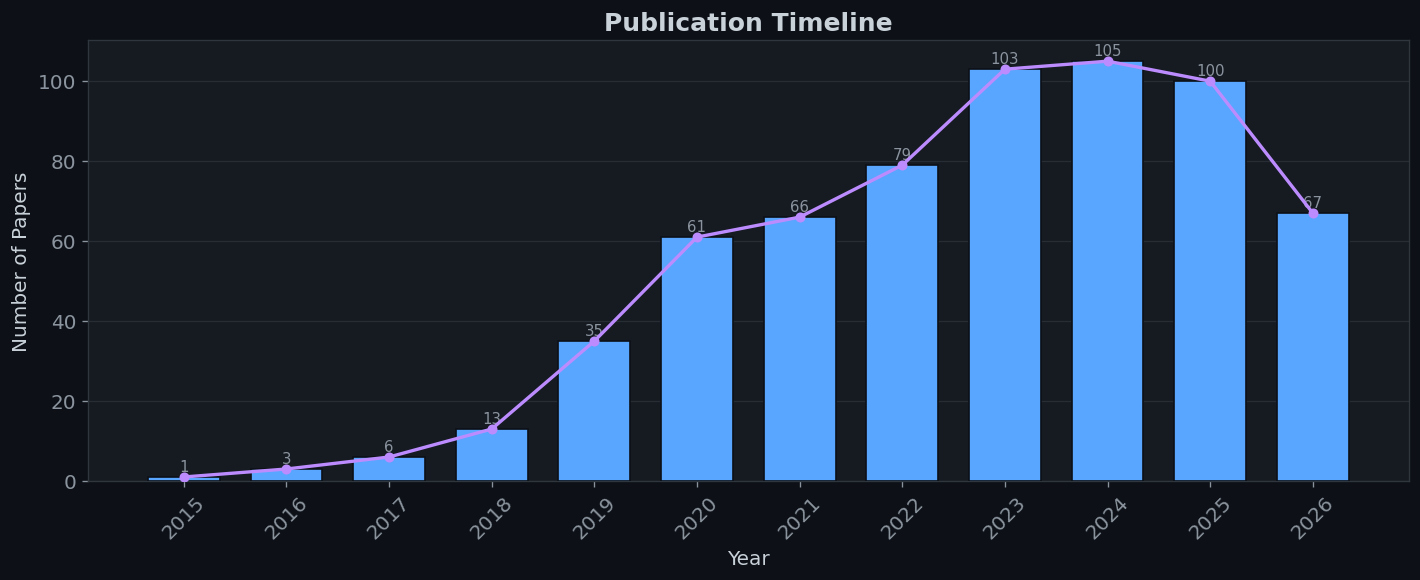

In [3]:
year_counts = df['year'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(year_counts.index.astype(str), year_counts.values,
              color=PALETTE[0], edgecolor='#0d1117', width=0.7, zorder=3)
ax.plot(year_counts.index.astype(str), year_counts.values,
        color=PALETTE[4], linewidth=2, marker='o', markersize=5, zorder=4)

for bar, val in zip(bars, year_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5,
            str(val), ha='center', fontsize=9, color='#8b949e')

ax.set_xlabel('Year')
ax.set_ylabel('Number of Papers')
ax.set_title('Publication Timeline')
ax.grid(axis='y', alpha=0.15, color='#8b949e')
ax.set_axisbelow(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('timeline.png', bbox_inches='tight', facecolor='#0d1117')
plt.show()

---
## 3. Journal vs Conference Split

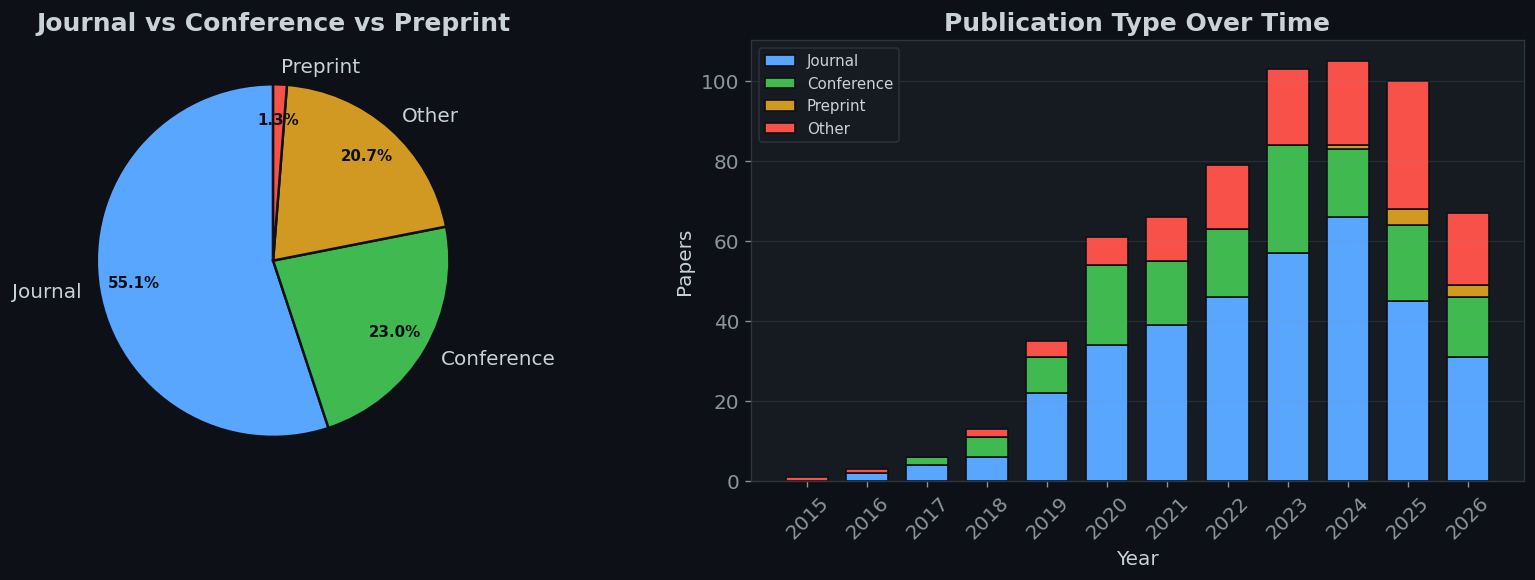

In [4]:
JOURNALS = {'TNSM','ACCESS','TVT','TMC','JIOT','JSAC','TNET','TWC','TCCN','OJCOMS',
            'MCOM','LCOMM','MNET','JNCA','JOCN','LNET','TNSE','COMST','WCL','MWC',
            'jcomnet','jcomcom','CST','FGCS','MONET','PPNA','SENSORS','NETWORK',
            'ELECTRONICS','electronics','JNSM','IOTJ','TII','TITS','TCOM','CL',
            'OJVT','JSYST','PIEEE','ETT','CCPE','OSN','CLUSTER'}
CONFERENCES = {'ICC','GLOBECOM','INFOCOM','CNSM','NOMS','CCNC','EuCNC','NetSoft',
               'WCNC','VTC','PIMRC','CAMAD','CSCN','NoF','5GWF','5GNet','5G-MeMU',
               'CNERT','HPSR','NFV-SDN','IM','MedComNet','CNSM','CloudNet',
               'AINA','ICNP','CloudCom','CCGRID','TCCN_conf','MSN','ICIN',
               'DRCN','ECOC','ONDM','OFC'}

def classify_type(v):
    vu = v.strip().upper() if isinstance(v, str) else ''
    vl = v.strip() if isinstance(v, str) else ''
    if vu.startswith('PREP'): return 'Preprint'
    if vl in JOURNALS or vu in {j.upper() for j in JOURNALS}: return 'Journal'
    if vl in CONFERENCES or vu in {c.upper() for c in CONFERENCES}: return 'Conference'
    # Heuristic: short acronyms with all-caps tend to be conferences
    return 'Other'

df['pub_type'] = df['venue_acronym'].apply(classify_type)
type_counts = df['pub_type'].value_counts()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Pie
colors_t = [PALETTE[0], PALETTE[1], PALETTE[2], PALETTE[3]]
wedges, texts, autotexts = ax1.pie(
    type_counts.values, labels=type_counts.index, autopct='%1.1f%%',
    colors=colors_t[:len(type_counts)], startangle=90, pctdistance=0.8,
    wedgeprops={'linewidth': 1.5, 'edgecolor': '#0d1117'},
)
for at in autotexts: at.set_fontsize(9); at.set_color('#0d1117'); at.set_fontweight('bold')
ax1.set_title('Journal vs Conference vs Preprint')

# Stacked timeline
years = sorted(df['year'].dropna().unique())
types = ['Journal', 'Conference', 'Preprint', 'Other']
type_colors = {t: c for t, c in zip(types, colors_t)}
bottom = np.zeros(len(years))
for t in types:
    if t not in df['pub_type'].values: continue
    vals = [len(df[(df['year']==y) & (df['pub_type']==t)]) for y in years]
    ax2.bar([str(y) for y in years], vals, bottom=bottom,
            label=t, color=type_colors.get(t, PALETTE[3]),
            edgecolor='#0d1117', width=0.7)
    bottom += vals
ax2.set_xlabel('Year')
ax2.set_ylabel('Papers')
ax2.set_title('Publication Type Over Time')
ax2.legend(loc='upper left', fontsize=9, facecolor='#161b22', edgecolor='#30363d')
ax2.grid(axis='y', alpha=0.15, color='#8b949e')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('journal_vs_conf.png', bbox_inches='tight', facecolor='#0d1117')
plt.show()

---
## 4. Top Venues

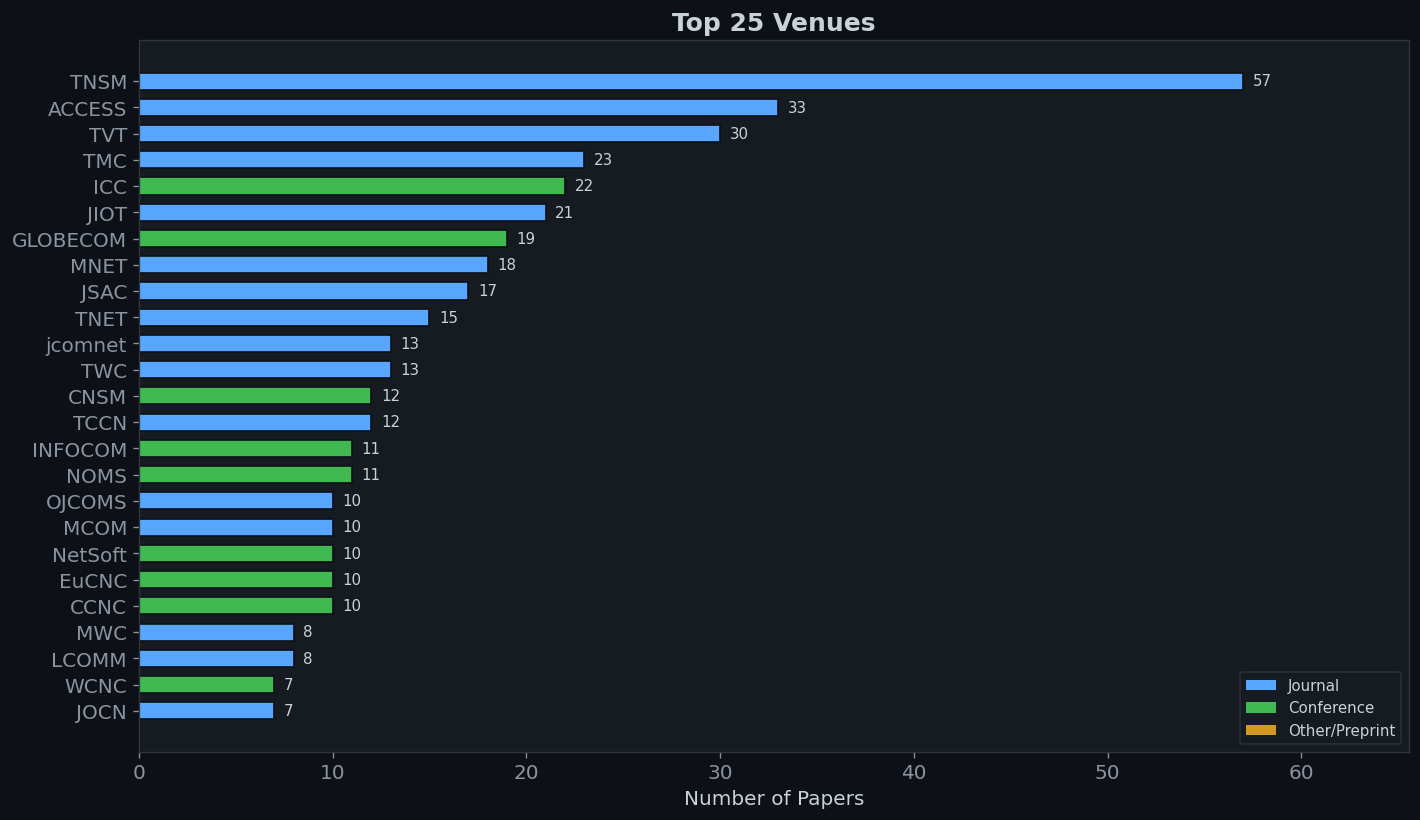

In [5]:
top_venues = df['venue_acronym'].value_counts().head(25)

fig, ax = plt.subplots(figsize=(12, 7))
colors_v = [PALETTE[0] if classify_type(v)=='Journal' else PALETTE[1] if classify_type(v)=='Conference' else PALETTE[2] for v in top_venues.index]
bars = ax.barh(top_venues.index[::-1], top_venues.values[::-1],
               color=colors_v[::-1], edgecolor='#0d1117', height=0.65)
for bar, val in zip(bars, top_venues.values[::-1]):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            str(val), va='center', fontsize=9, color='#c9d1d9')

# Legend
from matplotlib.patches import Patch
legend_items = [Patch(facecolor=PALETTE[0], label='Journal'),
                Patch(facecolor=PALETTE[1], label='Conference'),
                Patch(facecolor=PALETTE[2], label='Other/Preprint')]
ax.legend(handles=legend_items, loc='lower right', fontsize=9,
          facecolor='#161b22', edgecolor='#30363d')

ax.set_xlabel('Number of Papers')
ax.set_title('Top 25 Venues')
ax.set_xlim(0, top_venues.values[0] * 1.15)
plt.tight_layout()
plt.savefig('top_venues.png', bbox_inches='tight', facecolor='#0d1117')
plt.show()

In [4]:
import pandas as pd

# Robust load
df = pd.read_csv("litreview_filled.csv", encoding="utf-8-sig")
df.columns = (
    df.columns.astype(str)
    .str.replace("\ufeff", "", regex=False)
    .str.strip()
    .str.lower()
)

print("df type:", type(df))
print("columns:", df.columns.tolist())
print("title-like:", [c for c in df.columns if "title" in c])

required = ["title_official", "abstract", "venue_acronym", "year"]
missing = [c for c in required if c not in df.columns]
print("missing required:", missing)

df type: <class 'pandas.core.frame.DataFrame'>
columns: ['title_official', 'reference_key', 'venue_acronym', 'year', 'doi', 'abstract', 'first_author', 'filename']
title-like: ['title_official']
missing required: []


---
## 5. Word Cloud — Titles & Abstracts

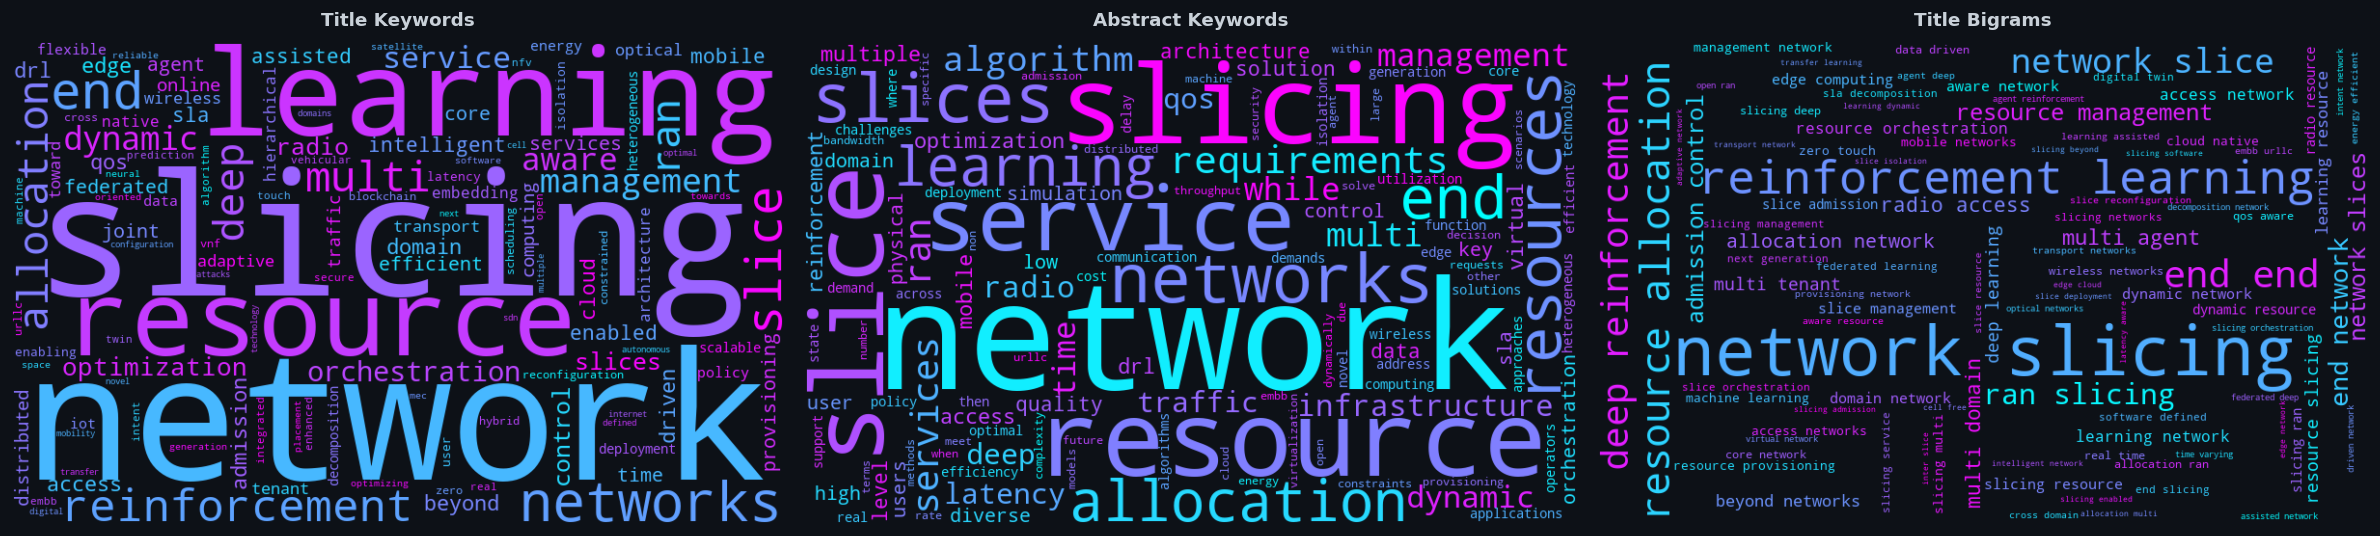

In [6]:
STOPWORDS = {'a','an','the','and','or','of','in','for','to','on','with','by','from',
             'is','are','was','were','be','been','this','that','these','those','it',
             'its','we','our','as','at','can','has','have','using','based','via',
             'through','into','between','over','under','also','such','more','most',
             'each','both','which','their','than','not','but','will','may','about',
             'paper','propose','proposed','approach','method','results','show',
             'performance','system','systems','problem','model','use','used',
             'study','analysis','however','new','two','first','scheme','framework',
             'consider','existing','different','provide','present','work','several',
             'one','well','demonstrates','demonstrate','evaluated','evaluate',
             'achieved','achieve','compared','various'}

def extract_words(text):
    if not isinstance(text, str): return []
    words = re.findall(r'[a-zA-Z]{2,}', text.lower())
    return [w for w in words if w not in STOPWORDS and len(w) > 2]

# Combine n-grams for meaningful compound terms
def extract_ngrams(text, n=2):
    if not isinstance(text, str): return []
    words = re.findall(r'[a-zA-Z]{2,}', text.lower())
    words = [w for w in words if w not in STOPWORDS and len(w) > 2]
    return [' '.join(words[i:i+n]) for i in range(len(words)-n+1)]

if "title_official" not in df.columns:
    raise KeyError(f"title_official not found. Available: {df.columns.tolist()}")

# Title words
title_words = []
for t in df['title_official']:
    title_words.extend(extract_words(t))

# Abstract words
abstract_words = []
for a in df['abstract'].dropna():
    abstract_words.extend(extract_words(a))

# Bigrams from titles
title_bigrams = []
for t in df['title_official']:
    title_bigrams.extend(extract_ngrams(t, 2))

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, words, title in zip(axes,
    [title_words, abstract_words, title_bigrams],
    ['Title Keywords', 'Abstract Keywords', 'Title Bigrams']):
    freq = Counter(words)
    wc = WordCloud(
        width=800, height=500,
        background_color='#0d1117',
        colormap='cool',
        max_words=120,
        min_font_size=8,
        prefer_horizontal=0.7,
        relative_scaling=0.5,
    ).generate_from_frequencies(freq)
    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(title, fontsize=11, fontweight='bold', pad=10)
    ax.axis('off')

plt.tight_layout()
plt.savefig('wordclouds.png', bbox_inches='tight', facecolor='#0d1117')
plt.show()

---
## 6. Top Keywords Bar Charts

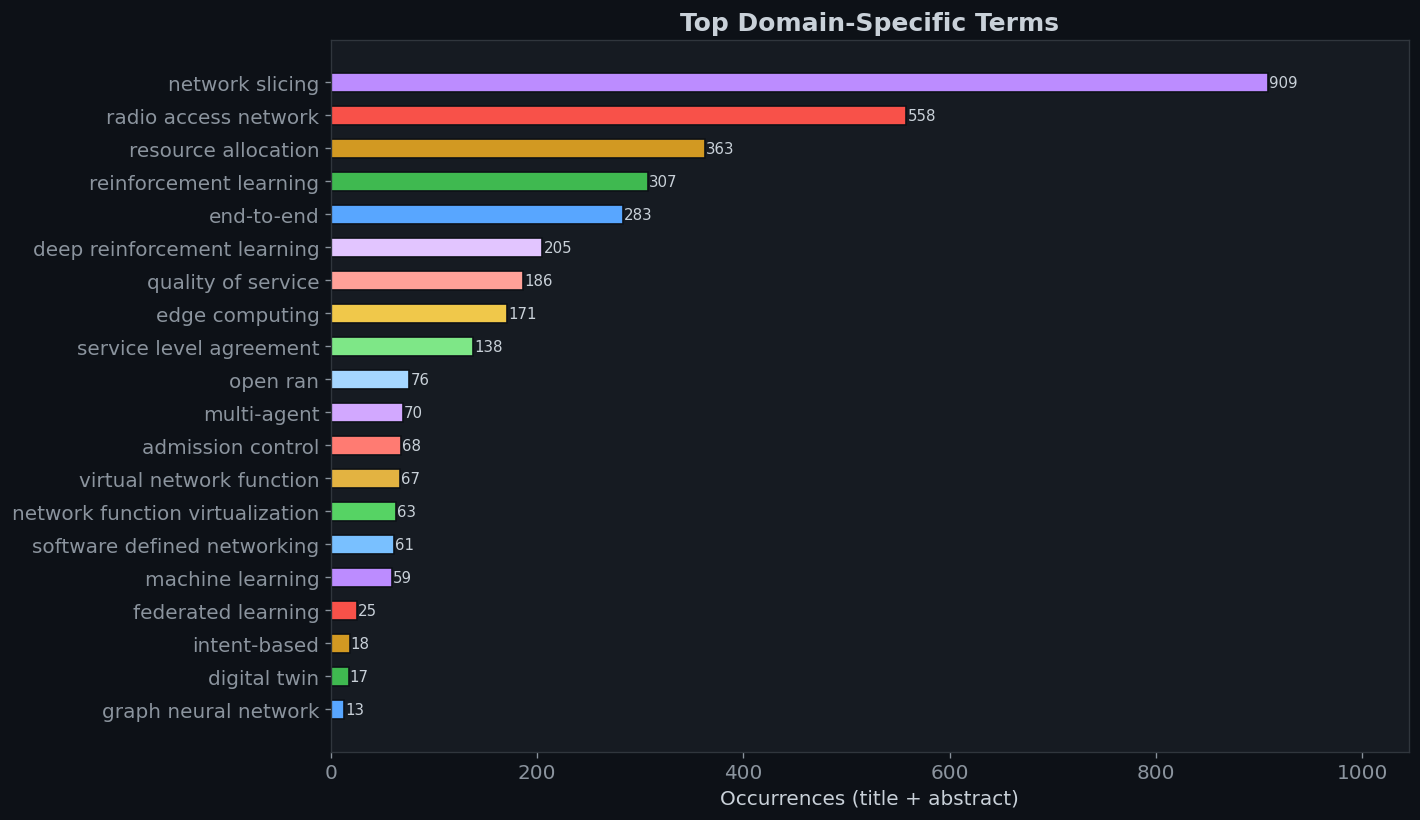

In [7]:
# Domain-aware compound terms to merge
COMPOUND_TERMS = {
    'network slicing': ['network slicing', 'network slice', 'network slices'],
    'resource allocation': ['resource allocation', 'resource management'],
    'deep reinforcement learning': ['deep reinforcement learning', 'deep rl'],
    'reinforcement learning': ['reinforcement learning'],
    'quality of service': ['quality of service', 'qos'],
    'machine learning': ['machine learning'],
    'service level agreement': ['service level agreement', 'sla'],
    'virtual network function': ['virtual network function', 'vnf', 'vnfs'],
    'software defined networking': ['software defined networking', 'sdn'],
    'network function virtualization': ['network function virtualization', 'nfv'],
    'radio access network': ['radio access network', 'ran'],
    'open ran': ['open ran', 'o-ran', 'oran'],
    'end-to-end': ['end to end', 'end-to-end', 'e2e'],
    'multi-agent': ['multi agent', 'multi-agent', 'multiagent'],
    'edge computing': ['edge computing', 'mec', 'mobile edge computing'],
    'admission control': ['admission control'],
    'digital twin': ['digital twin'],
    'intent-based': ['intent based', 'intent-based'],
    'federated learning': ['federated learning'],
    'transfer learning': ['transfer learning'],
    'graph neural network': ['graph neural network', 'gnn'],
}

def count_compound_terms(texts):
    counts = Counter()
    for text in texts:
        if not isinstance(text, str): continue
        tl = text.lower()
        for canonical, variants in COMPOUND_TERMS.items():
            for v in variants:
                if v in tl:
                    counts[canonical] += 1
                    break
    return counts

term_counts_title = count_compound_terms(df['title_official'])
term_counts_abstract = count_compound_terms(df['abstract'].dropna())
# Merge
term_counts_all = Counter()
for k in set(list(term_counts_title.keys()) + list(term_counts_abstract.keys())):
    term_counts_all[k] = term_counts_title.get(k, 0) + term_counts_abstract.get(k, 0)

top_terms = term_counts_all.most_common(20)

fig, ax = plt.subplots(figsize=(12, 7))
labels = [t[0] for t in top_terms][::-1]
vals = [t[1] for t in top_terms][::-1]
colors_bar = [PALETTE[i % len(PALETTE)] for i in range(len(labels))]
bars = ax.barh(labels, vals, color=colors_bar, edgecolor='#0d1117', height=0.6)
for bar, val in zip(bars, vals):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
            str(val), va='center', fontsize=9, color='#c9d1d9')
ax.set_xlabel('Occurrences (title + abstract)')
ax.set_title('Top Domain-Specific Terms')
ax.set_xlim(0, max(vals) * 1.15)
plt.tight_layout()
plt.savefig('top_terms.png', bbox_inches='tight', facecolor='#0d1117')
plt.show()

---
## 7. Top Prolific First Authors

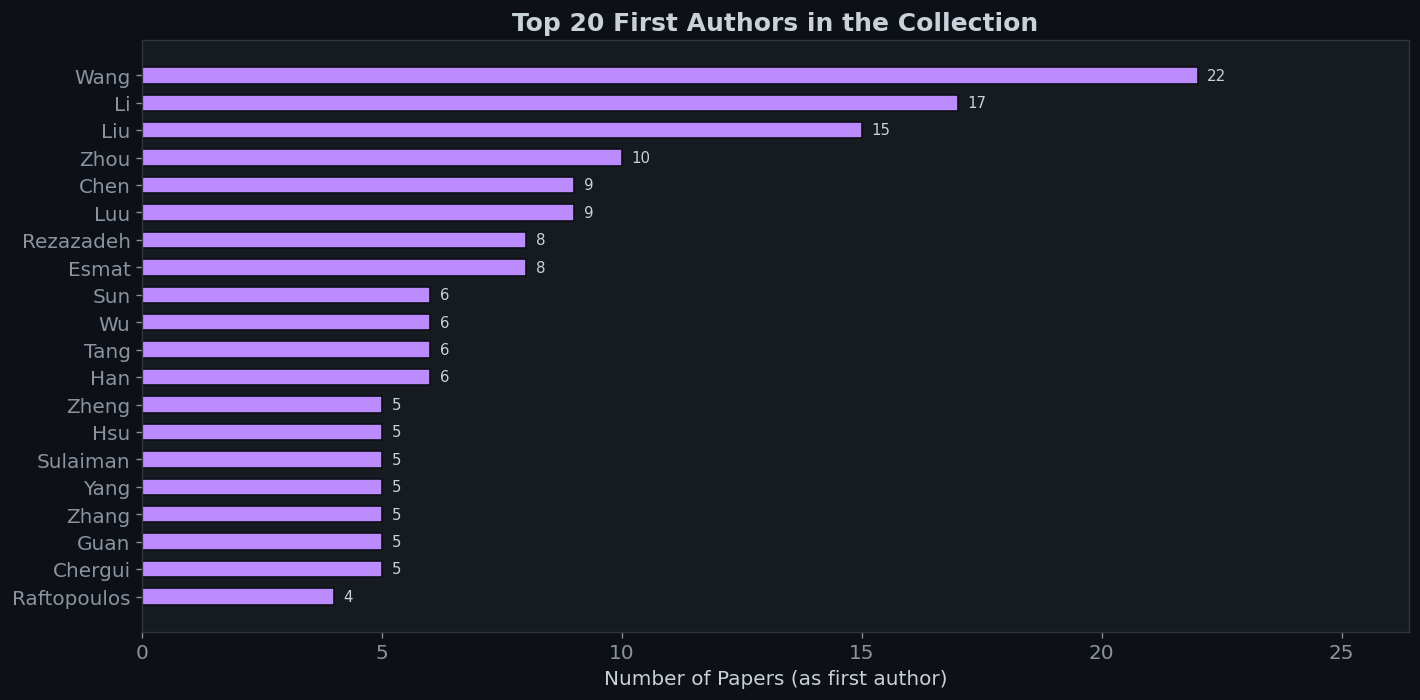

In [8]:
author_counts = df['first_author'].dropna().str.strip().value_counts()
author_counts = author_counts[author_counts.index != '']  # remove blanks
top_authors = author_counts.head(20)

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(top_authors.index[::-1], top_authors.values[::-1],
               color=PALETTE[4], edgecolor='#0d1117', height=0.6)
for bar, val in zip(bars, top_authors.values[::-1]):
    ax.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height()/2,
            str(val), va='center', fontsize=9, color='#c9d1d9')
ax.set_xlabel('Number of Papers (as first author)')
ax.set_title('Top 20 First Authors in the Collection')
ax.set_xlim(0, top_authors.values[0] * 1.2)
plt.tight_layout()
plt.savefig('top_authors.png', bbox_inches='tight', facecolor='#0d1117')
plt.show()

---
## 8. Topic Trends Over Time (Heatmap)

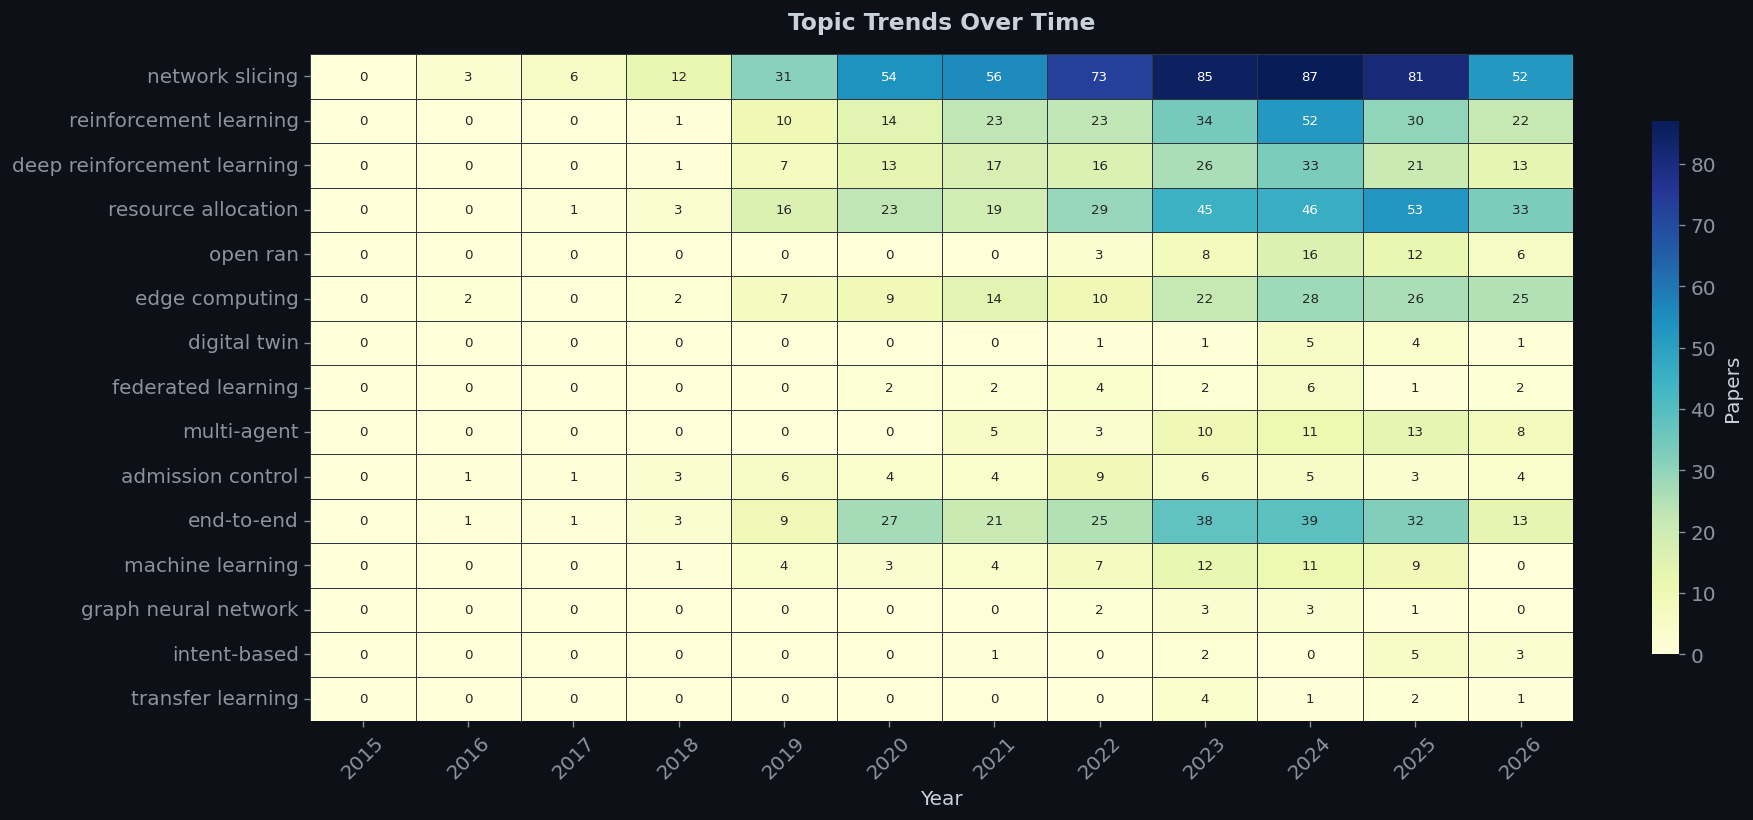

In [9]:
import seaborn as sns

TREND_TOPICS = [
    'network slicing', 'reinforcement learning', 'deep reinforcement learning',
    'resource allocation', 'open ran', 'edge computing', 'digital twin',
    'federated learning', 'multi-agent', 'admission control',
    'end-to-end', 'machine learning', 'graph neural network',
    'intent-based', 'transfer learning',
]

years = sorted(df['year'].dropna().unique())
heatmap_data = pd.DataFrame(0, index=TREND_TOPICS, columns=[str(int(y)) for y in years])

for _, row in df.iterrows():
    y = row['year']
    if pd.isna(y): continue
    combined = str(row.get('title_official','')) + ' ' + str(row.get('abstract',''))
    cl = combined.lower()
    for topic in TREND_TOPICS:
        variants = COMPOUND_TERMS.get(topic, [topic])
        for v in variants:
            if v in cl:
                heatmap_data.loc[topic, str(int(y))] += 1
                break

fig, ax = plt.subplots(figsize=(16, 7))
sns.heatmap(heatmap_data, annot=True, fmt='d', cmap='YlGnBu',
            linewidths=0.5, linecolor='#30363d', ax=ax,
            cbar_kws={'label': 'Papers', 'shrink': 0.8},
            annot_kws={'size': 8})
ax.set_title('Topic Trends Over Time', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Year')
ax.set_ylabel('')
plt.yticks(rotation=0)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('topic_heatmap.png', bbox_inches='tight', facecolor='#0d1117')
plt.show()

---
## 9. Venue × Year Bubble Chart (Top 10 Venues)

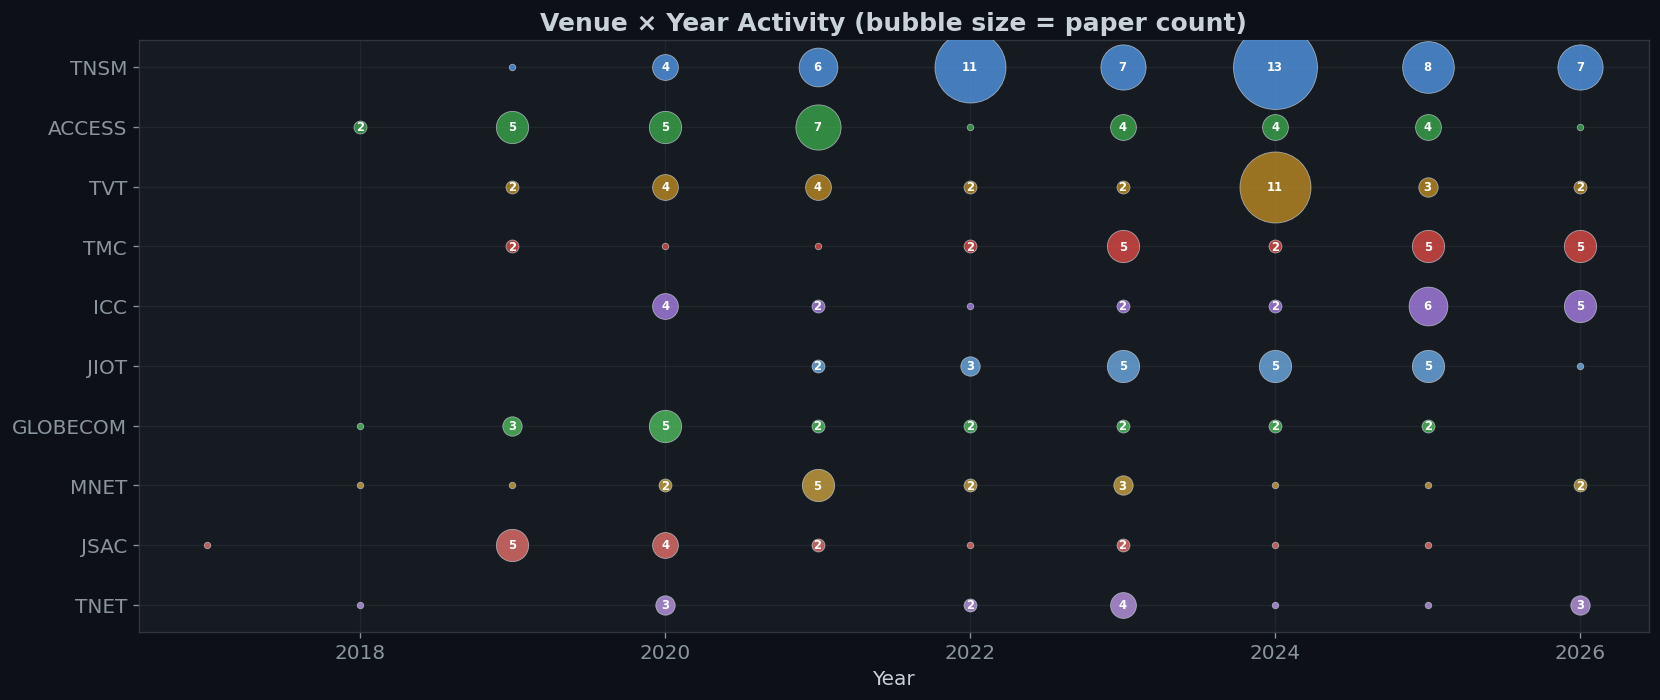

In [10]:
top10_venues = df['venue_acronym'].value_counts().head(10).index.tolist()
df_top = df[df['venue_acronym'].isin(top10_venues)].copy()

bubble = df_top.groupby(['venue_acronym', 'year']).size().reset_index(name='count')

fig, ax = plt.subplots(figsize=(14, 6))
venue_to_y = {v: i for i, v in enumerate(top10_venues)}

for _, row in bubble.iterrows():
    y_pos = venue_to_y[row['venue_acronym']]
    ax.scatter(row['year'], y_pos, s=row['count']**2 * 15,
               color=PALETTE[y_pos % len(PALETTE)], alpha=0.7,
               edgecolor='#c9d1d9', linewidth=0.5, zorder=3)
    if row['count'] >= 2:
        ax.text(row['year'], y_pos, str(row['count']),
                ha='center', va='center', fontsize=7, color='white', fontweight='bold')

ax.set_yticks(range(len(top10_venues)))
ax.set_yticklabels(top10_venues)
ax.set_xlabel('Year')
ax.set_title('Venue × Year Activity (bubble size = paper count)')
ax.grid(axis='both', alpha=0.1, color='#8b949e')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('venue_year_bubble.png', bbox_inches='tight', facecolor='#0d1117')
plt.show()

---
## 10. Abstract Length Distribution

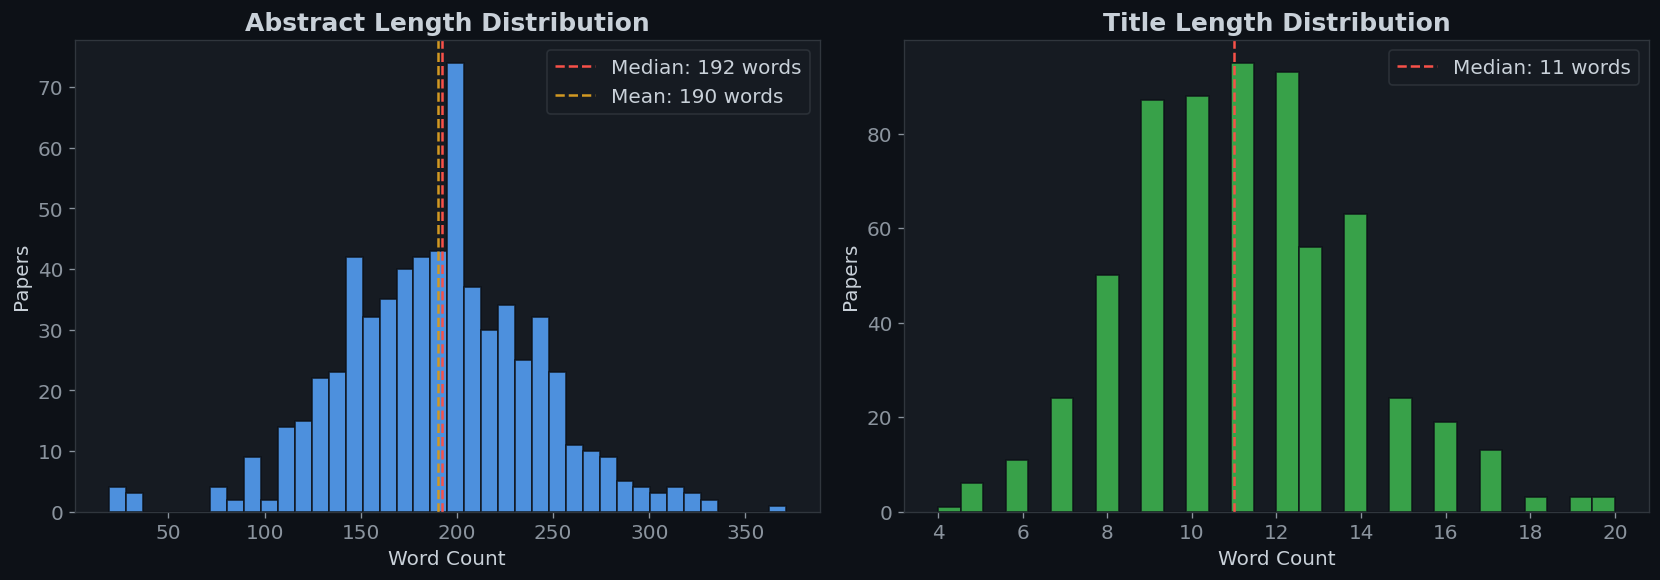

In [11]:
df['abstract_len'] = df['abstract'].apply(lambda x: len(str(x).split()) if isinstance(x, str) and x.strip() else 0)
df_with_abs = df[df['abstract_len'] > 0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.hist(df_with_abs['abstract_len'], bins=40, color=PALETTE[0],
         edgecolor='#0d1117', alpha=0.85)
ax1.axvline(df_with_abs['abstract_len'].median(), color=PALETTE[3],
            linestyle='--', linewidth=1.5, label=f"Median: {df_with_abs['abstract_len'].median():.0f} words")
ax1.axvline(df_with_abs['abstract_len'].mean(), color=PALETTE[2],
            linestyle='--', linewidth=1.5, label=f"Mean: {df_with_abs['abstract_len'].mean():.0f} words")
ax1.set_xlabel('Word Count')
ax1.set_ylabel('Papers')
ax1.set_title('Abstract Length Distribution')
ax1.legend(facecolor='#161b22', edgecolor='#30363d')

# Title length
df['title_len'] = df['title_official'].apply(lambda x: len(str(x).split()) if isinstance(x, str) else 0)
ax2.hist(df['title_len'], bins=30, color=PALETTE[1], edgecolor='#0d1117', alpha=0.85)
ax2.axvline(df['title_len'].median(), color=PALETTE[3],
            linestyle='--', linewidth=1.5, label=f"Median: {df['title_len'].median():.0f} words")
ax2.set_xlabel('Word Count')
ax2.set_ylabel('Papers')
ax2.set_title('Title Length Distribution')
ax2.legend(facecolor='#161b22', edgecolor='#30363d')

plt.tight_layout()
plt.savefig('length_dist.png', bbox_inches='tight', facecolor='#0d1117')
plt.show()

---
## 11. Summary Statistics

In [13]:
# Recompute all summary dependencies locally (order-independent)

# Safe derived columns
df["year"] = pd.to_numeric(df["year"], errors="coerce")

if "abstract_len" not in df.columns:
    df["abstract_len"] = df["abstract"].apply(
        lambda x: len(str(x).split()) if isinstance(x, str) and x.strip() else 0
    )

if "title_len" not in df.columns:
    df["title_len"] = df["title_official"].apply(
        lambda x: len(str(x).split()) if isinstance(x, str) else 0
    )

df_with_abs = df[df["abstract_len"] > 0]
year_counts = df["year"].dropna().astype(int).value_counts().sort_index()

# If publisher column is missing, rebuild it quickly
if "publisher" not in df.columns:
    def classify_publisher(doi):
        if not isinstance(doi, str):
            return "Unknown"
        d = doi.strip()
        if d.startswith("10.1109"): return "IEEE"
        if d.startswith("10.1016"): return "Elsevier"
        if d.startswith("10.3390"): return "MDPI"
        if d.startswith("10.1007"): return "Springer"
        if d.startswith("10.1145"): return "ACM"
        if d.startswith("10.1002"): return "Wiley"
        if d.startswith("10.36227"): return "TechRxiv"
        if d.startswith("10.48550"): return "arXiv"
        return "Other"

    df["publisher"] = df["doi"].apply(classify_publisher)

pub_counts = df["publisher"].value_counts()
venue_counts = df["venue_acronym"].value_counts()

print("=" * 60)
print(f"  Total papers:            {len(df)}")
print(f"  With abstract:           {df_with_abs.shape[0]} ({df_with_abs.shape[0]*100//len(df)}%)")
print(f"  With DOI:                {df['doi'].notna().sum()}")
print(f"  Unique venues:           {df['venue_acronym'].nunique()}")
print(f"  Unique first authors:    {df['first_author'].dropna().nunique()}")
print(f"  Year range:              {int(df['year'].min())}–{int(df['year'].max())}")
print(f"  Peak year:               {int(year_counts.idxmax())} ({year_counts.max()} papers)")
print(f"  Top venue:               {venue_counts.index[0]} ({venue_counts.values[0]} papers)")
print(f"  Top publisher:           {pub_counts.index[0]} ({pub_counts.values[0]} papers, {pub_counts.values[0]*100//len(df)}%)")
print(f"  Avg abstract length:     {df_with_abs['abstract_len'].mean():.0f} words")
print(f"  Avg title length:        {df['title_len'].mean():.1f} words")
print("=" * 60)

  Total papers:            639
  With abstract:           639 (100%)
  With DOI:                639
  Unique venues:           166
  Unique first authors:    379
  Year range:              2015–2026
  Peak year:               2024 (105 papers)
  Top venue:               TNSM (57 papers)
  Top publisher:           IEEE (503 papers, 78%)
  Avg abstract length:     190 words
  Avg title length:        11.2 words
